# Extractive Question Answering on SQuAD 1.1

Given a paragraph and a question, the model has to find the part of the paragraph that answers the question. It does this by predicting the start token and the end token of the answer.

Example: for the paragraph "Alan Turing was a British mathematician and computer scientist. He introduced the concept of the Turing machine in 1936." and the question "In which year did Alan Turing introduce the Turing machine?", the answer is "1936".

We compare three approaches:

1. A small Transformer encoder trained from scratch, in three versions:
    * 1a: random initialization, trained only on SQuAD
    * 1b: first pretrained with masked language modelling (MLM) on the SQuAD training text
    * 1c: first pretrained with MLM on WikiText-103 and the SQuAD training paragraphs
2. ELECTRA-base, fine-tuned, with the input cut at 384 tokens
3. RoBERTa-base, fine-tuned, with overlapping windows so long paragraphs are read completely

The notebook runs on Colab with a T4 GPU. Models, results and figures are stored in our Hugging Face repository [ummeabiha/squad-eqa-runs](https://huggingface.co/ummeabiha/squad-eqa-runs), which needs a token with write access saved as the Colab secret `HF_TOKEN`.

### Overview
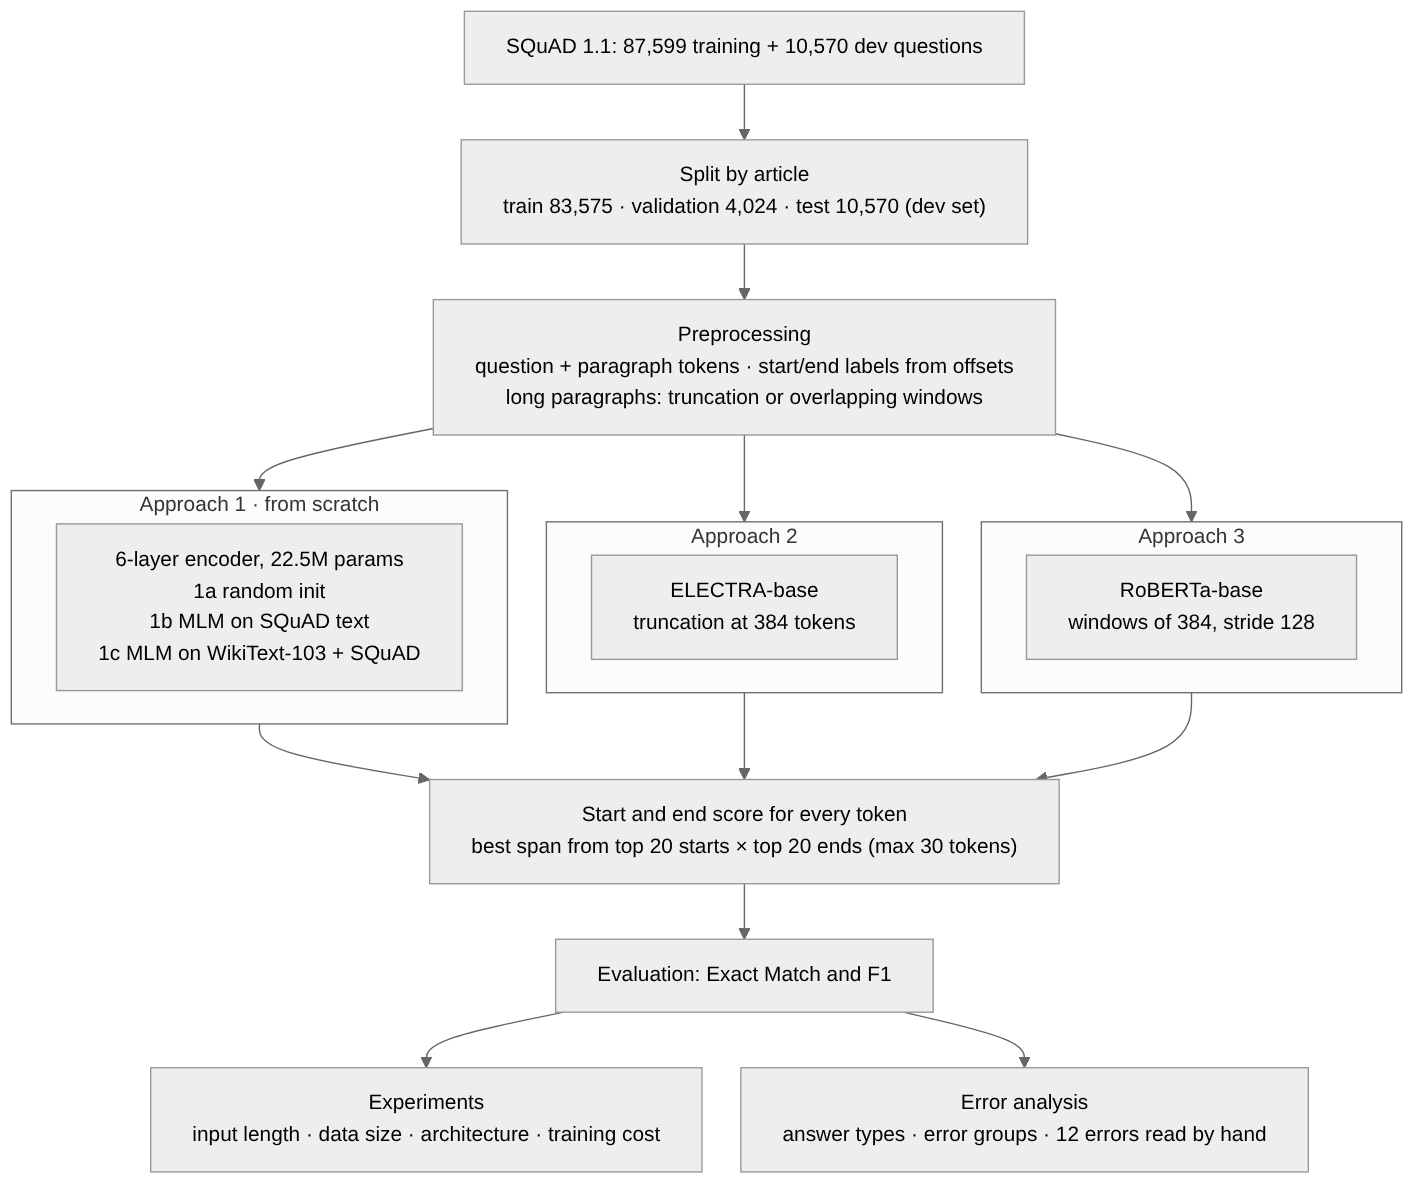




## 1. Setup

In [1]:
!pip install -q "transformers>=4.46" "datasets>=3.0" evaluate accelerate spacy
!python -m spacy download en_core_web_sm -q

✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [2]:
import os, re, json, time, random, string
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
import evaluate
import spacy
from datasets import load_dataset, Dataset, concatenate_datasets
from transformers import (AutoTokenizer, AutoModelForQuestionAnswering, DataCollatorForLanguageModeling,
                          Trainer, TrainingArguments, default_data_collator,
                          get_linear_schedule_with_warmup, set_seed)
from transformers.modeling_outputs import QuestionAnsweringModelOutput
from huggingface_hub import HfApi, snapshot_download

# no progress bars, fewer warnings
import datasets, transformers, huggingface_hub, logging
datasets.disable_progress_bars()
huggingface_hub.utils.disable_progress_bars()
transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)

SEED = 42
set_seed(SEED)
device = torch.device("cuda")
print(torch.cuda.get_device_name(0))
plt.rcParams["figure.dpi"] = 100

Tesla T4


In [3]:
from google.colab import userdata
os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")   # needs write access

HF_REPO = "ummeabiha/squad-eqa-runs"   # where all models, results and figures are kept
OUT = "/content/squad_qa"               # local working copy of the repository files
api = HfApi()
print("logged in as", api.whoami()["name"])

# results and figures that are already in the repository
snapshot_download(HF_REPO, local_dir=OUT, allow_patterns=["results/*", "figures/*"])
for folder in ["models", "results", "figures"]:
    os.makedirs(f"{OUT}/{folder}", exist_ok=True)


def upload(path, delete_patterns=None):
    """Upload a file or folder from OUT to the same place in the repository."""
    if os.path.isdir(f"{OUT}/{path}"):
        api.upload_folder(repo_id=HF_REPO, folder_path=f"{OUT}/{path}", path_in_repo=path, delete_patterns=delete_patterns)
    else:
        api.upload_file(repo_id=HF_REPO, path_or_fileobj=f"{OUT}/{path}", path_in_repo=path)


def save_fig(name):
    plt.savefig(f"{OUT}/figures/{name}", dpi=120, bbox_inches="tight")
    plt.show()
    upload(f"figures/{name}")

logged in as ummeabiha


## 2. Dataset

SQuAD 1.1 has about 88k training questions and 10.5k questions in the official dev set. Every answer is a span of its paragraph, given as text plus a character offset.

* train: the official training set without the validation articles
* validation: 5% of the training articles (seed 42). We hold out whole articles, so no validation paragraph is seen in training.
* test: the official dev set, used only for the final scores

In [4]:
squad = load_dataset("rajpurkar/squad")

titles = sorted(set(squad["train"]["title"]))
random.Random(SEED).shuffle(titles)
val_titles = set(titles[:round(0.05 * len(titles))])

train_set = squad["train"].filter(lambda ex: ex["title"] not in val_titles)
val_set = squad["train"].filter(lambda ex: ex["title"] in val_titles)
test_set = squad["validation"]
splits = {"train": train_set, "validation": val_set, "test": test_set}

pd.DataFrame([{"split": name, "questions": len(d), "paragraphs": len(set(d["context"])), "articles": len(set(d["title"])),
               "gold answers per question": round(np.mean([len(a["text"]) for a in d["answers"]]), 2)}
              for name, d in splits.items()])

,split,questions,paragraphs,articles,gold answers per question
0,train,83575,17952,420,1.00
1,validation,4024,939,22,1.00
2,test,10570,2067,48,3.29


Training and validation questions have one gold answer, test questions about three (written by different people). EM and F1 take the best match over the gold answers, so test scores are higher than validation scores for the same model.

### 2.1 Data checks

Every answer text should be at its `answer_start` position in the paragraph. We also look for duplicate ids and empty questions.

In [5]:
for name, d in splits.items():
    bad = sum(ex["context"][s:s + len(t)] != t for ex in d for t, s in zip(ex["answers"]["text"], ex["answers"]["answer_start"]))
    print(f"{name}: {bad} misaligned answers, {len(d) - len(set(d['id']))} duplicate ids, "
          f"{sum(not q.strip() for q in d['question'])} empty questions")

train: 0 misaligned answers, 0 duplicate ids, 0 empty questions
validation: 0 misaligned answers, 0 duplicate ids, 0 empty questions
test: 0 misaligned answers, 0 duplicate ids, 0 empty questions


Nothing needs to be removed. Some questions have extra spaces at the start or end, which we strip when tokenizing.

### 2.2 Exploratory analysis

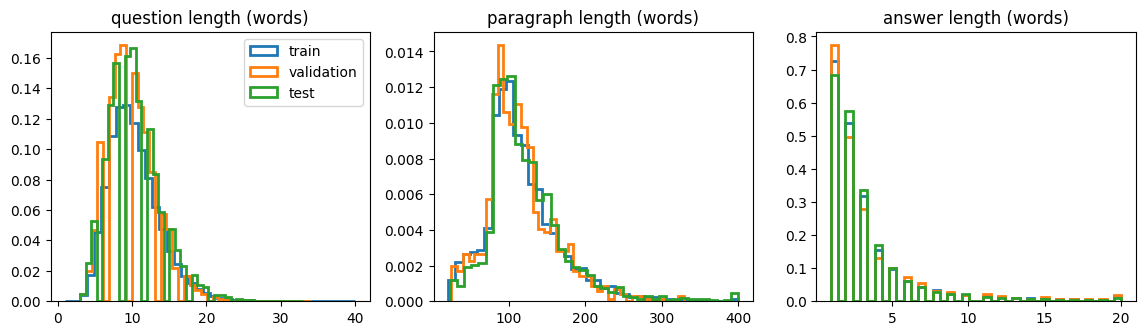

,train,validation,test
median question words,10.0,10.0,10.0
median paragraph words,107.0,107.0,111.0
median answer words,2.0,2.0,2.0


In [6]:
lengths = {name: {"question": [len(q.split()) for q in d["question"]],
                  "paragraph": [len(c.split()) for c in set(d["context"])],
                  "answer": [len(a["text"][0].split()) for a in d["answers"]]} for name, d in splits.items()}

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, field, limit in zip(axes, ["question", "paragraph", "answer"], [40, 400, 20]):
    for name in splits:
        ax.hist(np.clip(lengths[name][field], 0, limit), bins=40, density=True, histtype="step", linewidth=2, label=name)
    ax.set_title(f"{field} length (words)")
axes[0].legend()
save_fig("eda_word_lengths.png")

pd.DataFrame({name: {f"median {f} words": np.median(v) for f, v in fields.items()} for name, fields in lengths.items()})

Paragraphs are about 110 words long and most answers are 1 to 3 words. The models read tokens, not words, so we also count the tokens of question + paragraph. This shows how much text is lost when the input is cut at 128, 256 or 384 tokens.

longer than 128 tokens: 75.0% of training questions
longer than 256 tokens: 9.5% of training questions
longer than 384 tokens: 1.0% of training questions


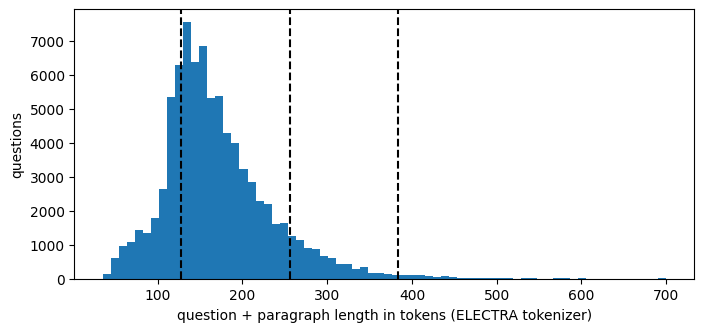

In [7]:
electra_tok = AutoTokenizer.from_pretrained("google/electra-base-discriminator")
contexts = sorted(set(train_set["context"]))
context_len = dict(zip(contexts, [len(ids) for ids in electra_tok(contexts)["input_ids"]]))
question_len = [len(ids) for ids in electra_tok(list(train_set["question"]), add_special_tokens=False)["input_ids"]]
token_lengths = np.array([q + context_len[c] for q, c in zip(question_len, train_set["context"])])

for limit in [128, 256, 384]:
    print(f"longer than {limit} tokens: {100 * np.mean(token_lengths > limit):.1f}% of training questions")

plt.figure(figsize=(8, 3.5))
plt.hist(np.clip(token_lengths, 0, 700), bins=70)
for limit in [128, 256, 384]:
    plt.axvline(limit, color="black", linestyle="--")
plt.xlabel("question + paragraph length in tokens (ELECTRA tokenizer)")
plt.ylabel("questions")
save_fig("eda_token_lengths.png")

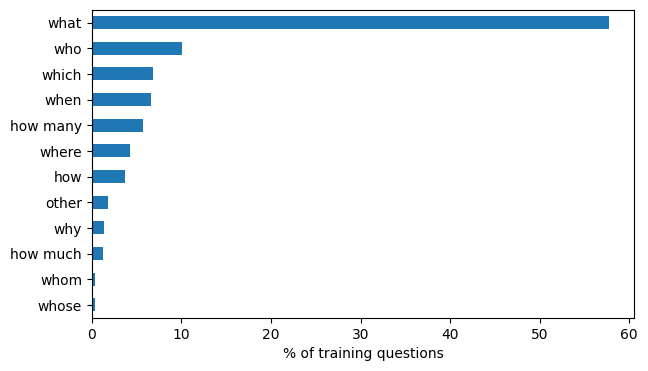

In [8]:
QUESTION_WORDS = ["how many", "how much", "what", "which", "who", "whom", "whose", "when", "where", "why", "how"]

def question_type(question):
    q = question.lower()
    found = [(m.start(), -len(w), w) for w in QUESTION_WORDS if (m := re.search(rf"\b{w}\b", q))]
    return min(found)[2] if found else "other"   # the first question word in the sentence

question_types = pd.Series([question_type(q) for q in train_set["question"]]).value_counts(normalize=True) * 100
question_types.sort_values().plot.barh(figsize=(7, 4), xlabel="% of training questions")
save_fig("eda_question_types.png")

More than half of the questions are "what" questions.

For the error analysis we also want to know what kind of answer each question has. We tag the answers with spaCy named entities and a few patterns, in this order: date, number, name (person, organisation or place), single word, multi-word phrase.

In [9]:
nlp = spacy.load("en_core_web_sm")
MONTHS = "january|february|march|april|may|june|july|august|september|october|november|december"
DATE_RE = re.compile(rf"\b(1[0-9]{{3}}|20[0-9]{{2}})s?\b|\b({MONTHS})\b|\b\d{{1,2}}(st|nd|rd|th) century\b", re.I)
NUMBER_RE = re.compile(r"\d|\b(one|two|three|four|five|six|seven|eight|nine|ten|eleven|twelve|twenty|thirty|forty|"
                       r"fifty|hundred|thousand|million|billion|dozen)\b", re.I)
ANSWER_TYPES = ["Date", "Number", "Name", "Single word", "Multi-word"]

def entity_labels(doc, start, end):
    # entities that cover at least half of the span
    return {e.label_ for e in doc.ents if min(end, e.end_char) - max(start, e.start_char) >= max(1, (end - start) / 2)}

def answer_type(text, labels):
    if "DATE" in labels or DATE_RE.search(text):
        return "Date"
    if labels & {"CARDINAL", "QUANTITY", "MONEY", "PERCENT"} or NUMBER_RE.search(text):
        return "Number"
    if labels & {"PERSON", "ORG", "GPE", "LOC", "FAC"}:
        return "Name"
    return "Single word" if len(text.split()) == 1 else "Multi-word"

docs = {c: doc for c, doc in zip(sorted(set(test_set["context"])), nlp.pipe(sorted(set(test_set["context"]))))}
test_types = []
for ex in test_set:
    text, start = ex["answers"]["text"][0], ex["answers"]["answer_start"][0]
    test_types.append(answer_type(text, entity_labels(docs[ex["context"]], start, start + len(text))))

(pd.Series(test_types).value_counts(normalize=True) * 100).reindex(ANSWER_TYPES).round(1)

,proportion
Date,11.4
Number,12.9
Name,24.1
Single word,13.3
Multi-word,38.2


## 3. Preprocessing

Question and paragraph go into the model together, for BERT-style tokenizers as `[CLS] question [SEP] paragraph [SEP]`. Only the paragraph is cut when the input is too long.

The labels are token positions. The offset mapping (the character span of every token) tells us which tokens are the first and last token of the answer. If the answer is not completely inside the input, both labels are 0 (the `[CLS]` token).

With overlapping windows a long paragraph is split into several inputs. Each new window starts `stride` tokens before the previous one ended, so an answer is never cut in half by the split. `make_windows` builds the windows one at a time and starts each new window at the beginning of a word.

In [10]:
def make_windows(tokenizer, question, context, max_len, stride, use_windows):
    windows, start = [], 0
    while True:
        cut = start - 1 if start > 0 and context[start - 1].isspace() else start   # keep the space before the word (RoBERTa)
        enc = tokenizer(question, context[cut:], truncation="only_second", max_length=max_len,
                        padding="max_length", return_offsets_mapping=True)
        seq_ids = enc.sequence_ids()
        # character offsets in the full paragraph, None for question and special tokens
        enc["offset_mapping"] = [(a + cut, b + cut) if s == 1 else None for (a, b), s in zip(enc["offset_mapping"], seq_ids)]
        windows.append(enc)
        if not use_windows or sum(enc["attention_mask"]) < max_len:   # the rest of the paragraph fitted
            return windows
        ctx = [i for i, s in enumerate(seq_ids) if s == 1]
        j = max(1, len(ctx) - stride)
        while j > 1 and not context[enc["offset_mapping"][ctx[j]][0] - 1].isspace():
            j -= 1   # start the next window at the beginning of a word
        start = enc["offset_mapping"][ctx[j]][0]


def tokenize_qa(examples, tokenizer, max_len, stride=0, use_windows=False):
    out = defaultdict(list)
    for i, ex_id in enumerate(examples["id"]):
        answer = examples["answers"][i]
        a_start = answer["answer_start"][0]
        a_end = a_start + len(answer["text"][0])
        for enc in make_windows(tokenizer, examples["question"][i].strip(), examples["context"][i], max_len, stride, use_windows):
            offsets = enc["offset_mapping"]
            ctx = [k for k, o in enumerate(offsets) if o is not None]
            if offsets[ctx[0]][0] <= a_start and offsets[ctx[-1]][1] >= a_end:
                start = next(k for k in ctx if offsets[k][1] > a_start)
                end = next(k for k in reversed(ctx) if offsets[k][0] < a_end)
            else:
                start = end = 0
            for key in ["input_ids", "attention_mask", "token_type_ids"]:
                if key in enc:
                    out[key].append(enc[key])
            out["offset_mapping"].append(offsets)
            out["example_id"].append(ex_id)
            out["start_positions"].append(start)
            out["end_positions"].append(end)
    return dict(out)


def make_features(data, tokenizer, max_len, stride=0, use_windows=False):
    return data.map(tokenize_qa, batched=True, remove_columns=data.column_names,
                    fn_kwargs=dict(tokenizer=tokenizer, max_len=max_len, stride=stride, use_windows=use_windows))


def answer_cutoff(examples, feats):
    # % of questions whose (first) gold answer is in none of the inputs
    found = {ex_id for ex_id, s in zip(feats["example_id"], feats["start_positions"]) if s > 0}
    return 100 * (1 - len(found) / len(examples))

Check: for 500 training questions we turn the labels back into text and compare them with the gold answer, and we count how many answers are lost at 128 tokens with and without windows.

In [11]:
sample = train_set.select(range(500))
for name, max_len, stride, windows in [("electra", 384, 0, False), ("electra", 128, 32, False), ("electra", 128, 32, True),
                                        ("roberta", 128, 32, True)]:
    tok = electra_tok if name == "electra" else AutoTokenizer.from_pretrained("roberta-base")
    feats = make_features(sample, tok, max_len, stride, windows)
    gold = dict(zip(sample["id"], [a["text"][0] for a in sample["answers"]]))
    context = dict(zip(sample["id"], sample["context"]))
    labelled = [(i, s, e, o) for i, s, e, o in zip(feats["example_id"], feats["start_positions"], feats["end_positions"],
                                                   feats["offset_mapping"]) if s > 0]
    same = np.mean([context[i][o[s][0]:o[e][1]] == gold[i] for i, s, e, o in labelled])
    print(f"{name} {max_len} tokens, windows={windows}: {len(feats) / len(sample):.2f} inputs per question, "
          f"answer lost for {answer_cutoff(sample, feats):.1f}%, label text = gold answer for {100 * same:.1f}%")

electra 384 tokens, windows=False: 1.00 inputs per question, answer lost for 0.8%, label text = gold answer for 99.6%
electra 128 tokens, windows=False: 1.00 inputs per question, answer lost for 28.0%, label text = gold answer for 99.4%
electra 128 tokens, windows=True: 2.62 inputs per question, answer lost for 0.0%, label text = gold answer for 99.5%
roberta 128 tokens, windows=True: 2.69 inputs per question, answer lost for 0.0%, label text = gold answer for 98.7%


With windows no answer is lost, even at 128 tokens. The few labels that do not match the gold text exactly are answers that end inside a token, for example the gold answer "six" inside the word "sixth".

## 4. Evaluation

### 4.1 Exact Match and F1

Both metrics first normalise the text: lowercase, remove punctuation and the articles a/an/the, and collapse spaces.
* Exact Match (EM): 1 if the normalised prediction equals a gold answer, else 0.
* F1: word overlap between the prediction and the gold answer (harmonic mean of precision and recall).

With several gold answers the best score counts. We wrote both metrics ourselves and compare them with the official SQuAD script.

In [12]:
def normalize(text):
    text = "".join(ch for ch in text.lower() if ch not in string.punctuation)
    text = re.sub(r"\b(a|an|the)\b", " ", text)
    return " ".join(text.split())

def exact_match(pred, gold):
    return float(normalize(pred) == normalize(gold))

def f1_score(pred, gold):
    p, g = normalize(pred).split(), normalize(gold).split()
    common = sum((Counter(p) & Counter(g)).values())
    if not p or not g:
        return float(p == g)
    if common == 0:
        return 0.0
    precision, recall = common / len(p), common / len(g)
    return 2 * precision * recall / (precision + recall)

def score(pred, golds):
    return max(exact_match(pred, g) for g in golds), max(f1_score(pred, g) for g in golds)

for pred, golds in [("1936", ["1936"]), ("in 1936", ["1936"]), ("The Turing machine", ["Turing machine"]),
                    ("Alan Turing", ["Turing", "Alan Mathison Turing"]), ("1937", ["1936"])]:
    print(f"{pred!r} vs {golds}: EM {score(pred, golds)[0]:.0f}, F1 {score(pred, golds)[1]:.2f}")

'1936' vs ['1936']: EM 1, F1 1.00
'in 1936' vs ['1936']: EM 0, F1 0.67
'The Turing machine' vs ['Turing machine']: EM 1, F1 1.00
'Alan Turing' vs ['Turing', 'Alan Mathison Turing']: EM 0, F1 0.80
'1937' vs ['1936']: EM 0, F1 0.00


In [13]:
squad_metric = evaluate.load("squad")

def official_scores(preds, examples):
    return squad_metric.compute(predictions=[{"id": ex["id"], "prediction_text": preds[ex["id"]]["text"]} for ex in examples],
                                references=[{"id": ex["id"], "answers": ex["answers"]} for ex in examples])

# compare with the official script on some made-up predictions
check = val_set.select(range(200))
fake = {ex["id"]: {"text": [ex["answers"]["text"][0], "the " + ex["answers"]["text"][0].upper(), ex["context"][:20], ""][i % 4]}
        for i, ex in enumerate(check)}
ours = np.mean([score(fake[ex["id"]]["text"], ex["answers"]["text"]) for ex in check], axis=0) * 100
print("ours:    ", ours.round(4))
print("official:", official_scores(fake, check))

ours:     [50.     50.5893]
official: {'exact_match': 50.0, 'f1': 50.589285714285715}


### 4.2 From scores to an answer

The model gives a start score and an end score for every token. For each input we take the 20 best start and 20 best end positions, keep the pairs that lie inside the paragraph, have end >= start and are at most 30 tokens long, and pick the pair with the highest start + end score. With windows, the best pair over all windows of the question wins.

In [14]:
@torch.no_grad()
def get_logits(model, feats, batch_size=64):
    model.eval()
    cols = [c for c in ["input_ids", "attention_mask", "token_type_ids", "start_positions", "end_positions"] if c in feats.column_names]
    data = feats.select_columns(cols).with_format("torch")
    starts, ends, losses = [], [], []
    for i in range(0, len(data), batch_size):
        batch = {k: v.to(device) for k, v in data[i:i + batch_size].items()}
        with torch.autocast("cuda", dtype=torch.float16):
            out = model(**batch)
        starts.append(out.start_logits.float().cpu().numpy())
        ends.append(out.end_logits.float().cpu().numpy())
        losses.append(out.loss.item())
    return np.concatenate(starts), np.concatenate(ends), float(np.mean(losses))


def postprocess(examples, feats, start_logits, end_logits, n_best=20, max_answer_len=30):
    inputs_of = defaultdict(list)
    for i, ex_id in enumerate(feats["example_id"]):
        inputs_of[ex_id].append(i)
    all_offsets = feats["offset_mapping"]
    preds = {}
    for ex in examples:
        best = {"text": "", "start": None, "score": -1e9}
        for i in inputs_of[ex["id"]]:
            offsets = all_offsets[i]
            for s in np.argsort(start_logits[i])[-n_best:]:
                for e in np.argsort(end_logits[i])[-n_best:]:
                    if offsets[s] is None or offsets[e] is None or e < s or e - s + 1 > max_answer_len:
                        continue
                    if start_logits[i][s] + end_logits[i][e] > best["score"]:
                        best = {"text": ex["context"][offsets[s][0]:offsets[e][1]], "start": offsets[s][0],
                                "score": float(start_logits[i][s] + end_logits[i][e])}
        preds[ex["id"]] = best
    return preds


def evaluate_model(model, examples, feats):
    torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    start_logits, end_logits, loss = get_logits(model, feats)
    preds = postprocess(examples, feats, start_logits, end_logits)
    seconds = time.time() - t0
    scores = official_scores(preds, examples)
    return {"em": scores["exact_match"], "f1": scores["f1"], "loss": loss, "seconds_per_1000": 1000 * seconds / len(examples),
            "inference_gpu_gb": torch.cuda.max_memory_allocated() / 1e9}, preds

### 4.3 Saving and loading models

Every model has a folder under `models/` in the repository with its weights, a `qa_run_config.json` (maximum length, stride and, for the scratch models, the architecture) and an `info.json` with the training curves, training time and GPU memory. `fetch_model` downloads the folder. If a model is not in the repository yet, it is trained in the next sections.

In [15]:
FOLDER = {"scratch": "scratch_f9ed439f", "scratch_squad_mlm": "scratch_mlm_d5ed7f75", "scratch_wiki_mlm": "scratch_wiki_mlm",
          "electra": "electra_56b9af30", "roberta": "roberta_26dc0834"}
TOKENIZER_OF = {"scratch": "bert-base-uncased", "electra": "google/electra-base-discriminator", "roberta": "roberta-base"}


def model_dir(name):
    return f"{OUT}/models/{FOLDER[name]}"


def fetch_model(name):
    """Download a model from the repository. Returns False if it has not been trained yet."""
    folder = FOLDER[name]
    snapshot_download(HF_REPO, local_dir=OUT, allow_patterns=[f"models/{folder}/*"])
    if not os.path.exists(f"{model_dir(name)}/qa_run_config.json"):
        return False   # not there, or only a checkpoint of an unfinished run
    # save the tokenizer again with the installed transformers version
    AutoTokenizer.from_pretrained(TOKENIZER_OF[name.split("_")[0]]).save_pretrained(model_dir(name))
    if not os.path.exists(f"{model_dir(name)}/info.json"):   # older folders: curves are in the training log
        with open(f"{OUT}/results/runs/{folder}.json") as f:
            record = json.load(f)
        info = {"train_log": [{"epoch": h["epoch"], "loss": h["train_loss"]} for h in record["history"] if h["kind"] == "train"],
                "val_log": [{"epoch": h["epoch"], "loss": h["eval_loss"], "f1": h["eval_f1"]} for h in record["history"] if h["kind"] == "eval"],
                "train_seconds": record.get("finetune_seconds", record["train_seconds"]), "train_gpu_gb": record["peak_train_gpu_gb"],
                "epochs": record["epochs_completed"], "mlm_log": record.get("mlm_history", []),
                "mlm_seconds": record.get("mlm_seconds", 0)}
        with open(f"{model_dir(name)}/info.json", "w") as f:
            json.dump(info, f)
    print("downloaded", name)
    return True


def load_model(name):
    folder = model_dir(name)
    with open(f"{folder}/qa_run_config.json") as f:
        config = json.load(f)
    if config["kind"] == "scratch":
        model = ScratchQAModel(**config["arch"])
        model.load_state_dict(torch.load(f"{folder}/best_model.pt", map_location="cpu"))
    else:
        model = AutoModelForQuestionAnswering.from_pretrained(folder)
    with open(f"{folder}/info.json") as f:
        info = json.load(f)
    return model.to(device), config, info

## 5. Approach 1: Transformer encoder trained from scratch

This model has no pretrained weights, so it shows how much the pretrained models of approaches 2 and 3 gain from pretraining.

| Part | Setting |
|---|---|
| Tokenizer | `bert-base-uncased` vocabulary (30,522 tokens), only the vocabulary is used |
| Embeddings | token + position + segment (question or paragraph) + exact-match feature |
| Encoder | 6 Transformer layers, hidden size 384, 6 attention heads, feed-forward 1536, GELU, pre-norm |
| Heads | two linear layers on every token: one gives the start score, one the end score |
| Loss | (cross entropy of start + cross entropy of end) / 2 |
| Max length | 256 tokens, longer paragraphs are truncated |

The exact-match feature (from DrQA, Chen et al. 2017) marks paragraph tokens that also appear in the question. It needs no outside data and helps a model without pretraining to find the part of the paragraph the question is about.

In [16]:
class ScratchQAModel(nn.Module):
    def __init__(self, vocab_size, hidden=384, layers=6, heads=6, ff_dim=1536, max_len=256, dropout=0.1, pad_id=0):
        super().__init__()
        self.token_emb = nn.Embedding(vocab_size, hidden, padding_idx=pad_id)
        self.pos_emb = nn.Embedding(max_len, hidden)
        self.seg_emb = nn.Embedding(2, hidden)
        self.match_emb = nn.Embedding(2, hidden)
        self.emb_norm = nn.LayerNorm(hidden)
        self.emb_drop = nn.Dropout(dropout)
        layer = nn.TransformerEncoderLayer(hidden, heads, ff_dim, dropout, activation="gelu", batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, layers, norm=nn.LayerNorm(hidden), enable_nested_tensor=False)
        self.start_head = nn.Linear(hidden, 1)
        self.end_head = nn.Linear(hidden, 1)

    def encode(self, input_ids, attention_mask, token_type_ids):
        positions = torch.arange(input_ids.size(1), device=input_ids.device)
        question = (token_type_ids == 0) & (attention_mask == 1)
        # exact match: 1 if the same token id appears in the question part
        match = ((input_ids[:, :, None] == input_ids[:, None, :]) & question[:, None, :]).any(-1).long()
        x = self.token_emb(input_ids) + self.pos_emb(positions) + self.seg_emb(token_type_ids) + self.match_emb(match)
        x = self.emb_drop(self.emb_norm(x))
        return self.encoder(x, src_key_padding_mask=attention_mask == 0)

    def forward(self, input_ids, attention_mask, token_type_ids, start_positions=None, end_positions=None):
        h = self.encode(input_ids, attention_mask, token_type_ids)
        padding = attention_mask == 0
        start_logits = self.start_head(h).squeeze(-1).masked_fill(padding, -1e4)
        end_logits = self.end_head(h).squeeze(-1).masked_fill(padding, -1e4)
        loss = None
        if start_positions is not None:
            loss = (F.cross_entropy(start_logits.float(), start_positions) + F.cross_entropy(end_logits.float(), end_positions)) / 2
        return QuestionAnsweringModelOutput(loss=loss, start_logits=start_logits, end_logits=end_logits)


scratch_tok = AutoTokenizer.from_pretrained("bert-base-uncased")
ARCH = {"vocab_size": scratch_tok.vocab_size, "hidden": 384, "layers": 6, "heads": 6, "ff_dim": 1536,
        "max_len": 256, "dropout": 0.1, "pad_id": scratch_tok.pad_token_id}
print(f"{sum(p.numel() for p in ScratchQAModel(**ARCH).parameters()):,} parameters")

22,469,378 parameters


### 5.1 Training loop

AdamW, 10% warmup then linear decay, batch 64, gradient clipping at 1.0, fp16. After every epoch we score the validation set and keep the weights with the best F1. Training stops when F1 has not improved for 3 epochs. A checkpoint is uploaded after every epoch, so a run that is cut off continues where it stopped.

In [17]:
scratch_train = make_features(train_set, scratch_tok, 256).remove_columns(["offset_mapping", "example_id"])
scratch_val = make_features(val_set, scratch_tok, 256)


def train_scratch(name, init_weights=None, epochs=15, lr=5e-4, patience=3, batch_size=64):
    folder = model_dir(name)
    os.makedirs(folder, exist_ok=True)
    model = ScratchQAModel(**ARCH).to(device)
    if init_weights:   # encoder from MLM pretraining, the start/end heads stay random
        model.load_state_dict(torch.load(init_weights), strict=False)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    loader = DataLoader(scratch_train.with_format("torch"), batch_size=batch_size, shuffle=True)
    total_steps = epochs * len(loader)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda")
    state = {"epoch": 0, "best_f1": -1, "bad_epochs": 0, "seconds": 0, "train_log": [], "val_log": []}

    checkpoint = f"{folder}/checkpoint.pt"
    if os.path.exists(checkpoint):
        saved = torch.load(checkpoint, weights_only=False)
        model.load_state_dict(saved["model"])
        optimizer.load_state_dict(saved["optimizer"])
        scheduler.load_state_dict(saved["scheduler"])
        state = saved["state"]
        print("continuing after epoch", state["epoch"])

    torch.cuda.reset_peak_memory_stats()
    while state["epoch"] < epochs and state["bad_epochs"] < patience:
        t0 = time.time()
        model.train()
        losses = []
        for batch in loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            with torch.autocast("cuda", dtype=torch.float16):
                loss = model(**batch).loss
            optimizer.zero_grad()
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            losses.append(loss.item())

        val, _ = evaluate_model(model, val_set, scratch_val)
        state["epoch"] += 1
        state["seconds"] += time.time() - t0
        state["train_log"].append({"epoch": state["epoch"], "loss": float(np.mean(losses))})
        state["val_log"].append({"epoch": state["epoch"], "loss": val["loss"], "f1": val["f1"]})
        print(f"epoch {state['epoch']}: train loss {np.mean(losses):.3f}, val loss {val['loss']:.3f}, "
              f"val EM {val['em']:.2f}, val F1 {val['f1']:.2f}")
        if val["f1"] > state["best_f1"]:
            state["best_f1"], state["bad_epochs"] = val["f1"], 0
            torch.save(model.state_dict(), f"{folder}/best_model.pt")
        else:
            state["bad_epochs"] += 1
        torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                    "scheduler": scheduler.state_dict(), "state": state}, checkpoint)
        upload(f"models/{FOLDER[name]}")

    with open(f"{folder}/qa_run_config.json", "w") as f:
        json.dump({"kind": "scratch", "arch": ARCH, "max_len": 256, "stride": 64}, f)
    info = {"train_log": state["train_log"], "val_log": state["val_log"], "train_seconds": state["seconds"],
            "train_gpu_gb": torch.cuda.max_memory_allocated() / 1e9, "epochs": state["epoch"]}
    if os.path.exists(f"{folder}/mlm_info.json"):
        with open(f"{folder}/mlm_info.json") as f:
            info.update(json.load(f))
    with open(f"{folder}/info.json", "w") as f:
        json.dump(info, f)
    os.remove(checkpoint)
    scratch_tok.save_pretrained(folder)
    upload(f"models/{FOLDER[name]}", delete_patterns=["checkpoint.pt"])

### 5.2 Pretraining with masked language modelling

Trained only on SQuAD, the scratch model (1a) learns the training answers but does not generalise: its training loss keeps falling while the validation loss goes up after epoch 9. It has never seen any other English text.

So for 1b and 1c we first pretrain the same encoder with masked language modelling, as in BERT. 15% of the tokens are picked; 80% of them are replaced by `[MASK]`, 10% by a random token and 10% stay the same, and the model has to predict the original tokens. A small MLM head is used for this and thrown away afterwards.

* 1b: 20 epochs on the SQuAD training question-paragraph pairs, so no outside data. The corpus is small: about 18k paragraphs, each repeated with every question about it.
* 1c: WikiText-103 (Merity et al. 2016, about 100M words from Wikipedia) plus the SQuAD training paragraphs, cut into blocks of 256 tokens. All tokens get the paragraph segment id, since that is the kind of text the model reads later.

WikiText-103 and SQuAD both come from Wikipedia, so a few test paragraphs may also be in the pretraining text (without questions or answers). ELECTRA and RoBERTa were pretrained on Wikipedia as well.

In [18]:
class ScratchMLM(nn.Module):
    def __init__(self, qa_model):
        super().__init__()
        self.qa = qa_model
        hidden, vocab = qa_model.token_emb.embedding_dim, qa_model.token_emb.num_embeddings
        self.head = nn.Sequential(nn.Linear(hidden, hidden), nn.GELU(), nn.LayerNorm(hidden), nn.Linear(hidden, vocab))

    def forward(self, input_ids, attention_mask, labels):
        h = self.qa.encode(input_ids, attention_mask, torch.ones_like(input_ids))   # segment 1 = paragraph text
        masked = labels != -100
        logits = self.head(h[masked]).float()   # only the masked positions are predicted
        return F.cross_entropy(logits, labels[masked]), (logits.argmax(-1) == labels[masked]).float().mean()


def pack_text(batch, block=256):
    ids = scratch_tok(batch["text"], add_special_tokens=False)["input_ids"]
    flat = [t for seq in ids for t in seq + [scratch_tok.sep_token_id]]
    size = block - 2
    blocks = [[scratch_tok.cls_token_id] + flat[i:i + size] + [scratch_tok.sep_token_id]
              for i in range(0, len(flat) - size + 1, size)]
    return {"input_ids": blocks, "attention_mask": [[1] * block for _ in blocks]}


def make_mlm_data(texts):
    return Dataset.from_dict({"text": texts}).map(pack_text, batched=True, batch_size=1000, remove_columns=["text"])

In [19]:
def pretrain_mlm(name, train_data, val_data, epochs, lr=5e-4, batch_size=64):
    folder = model_dir(name)
    os.makedirs(folder, exist_ok=True)
    if os.path.exists(f"{folder}/mlm_encoder.pt"):
        print("pretraining already done")
        return f"{folder}/mlm_encoder.pt"
    model = ScratchMLM(ScratchQAModel(**ARCH)).to(device)
    collator = DataCollatorForLanguageModeling(scratch_tok, mlm_probability=0.15)
    loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, collate_fn=collator)
    val_loader = DataLoader(val_data, batch_size=128, collate_fn=collator)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.06 * epochs * len(loader)), epochs * len(loader))
    scaler = torch.amp.GradScaler("cuda")
    state = {"epoch": 0, "seconds": 0, "log": []}

    checkpoint = f"{folder}/mlm_checkpoint.pt"
    if os.path.exists(checkpoint):
        saved = torch.load(checkpoint, weights_only=False)
        model.load_state_dict(saved["model"])
        optimizer.load_state_dict(saved["optimizer"])
        scheduler.load_state_dict(saved["scheduler"])
        state = saved["state"]
        print("continuing after epoch", state["epoch"])

    while state["epoch"] < epochs:
        t0 = time.time()
        model.train()
        losses = []
        for batch in loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            with torch.autocast("cuda", dtype=torch.float16):
                loss, _ = model(**batch)
            optimizer.zero_grad()
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            losses.append(loss.item())

        model.eval()
        rng = torch.get_rng_state()
        torch.manual_seed(SEED)   # same masks for the validation text every epoch
        val_loss, val_acc = [], []
        with torch.no_grad():
            for batch in val_loader:
                batch = {k: v.to(device) for k, v in batch.items()}
                with torch.autocast("cuda", dtype=torch.float16):
                    loss, acc = model(**batch)
                val_loss.append(loss.item())
                val_acc.append(acc.item())
        torch.set_rng_state(rng)
        state["epoch"] += 1
        state["seconds"] += time.time() - t0
        state["log"].append({"epoch": state["epoch"], "train_loss": float(np.mean(losses)),
                             "val_loss": float(np.mean(val_loss)), "val_acc": float(np.mean(val_acc))})
        print(f"MLM epoch {state['epoch']}: train loss {np.mean(losses):.3f}, val loss {np.mean(val_loss):.3f}, "
              f"val accuracy {100 * np.mean(val_acc):.1f}%")
        torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                    "scheduler": scheduler.state_dict(), "state": state}, checkpoint)
        upload(f"models/{FOLDER[name]}/mlm_checkpoint.pt")

    encoder = {k: v for k, v in model.qa.state_dict().items() if not k.startswith(("start_head", "end_head"))}
    torch.save(encoder, f"{folder}/mlm_encoder.pt")
    with open(f"{folder}/mlm_info.json", "w") as f:
        json.dump({"mlm_log": state["log"], "mlm_seconds": state["seconds"]}, f)
    os.remove(checkpoint)
    upload(f"models/{FOLDER[name]}", delete_patterns=["mlm_checkpoint.pt"])
    return f"{folder}/mlm_encoder.pt"

### 5.3 Training the three scratch models

In [20]:
if not fetch_model("scratch"):
    train_scratch("scratch", lr=5e-4)

if not fetch_model("scratch_squad_mlm"):
    squad_text = [q + " " + c for q, c in zip(train_set["question"], train_set["context"])]
    encoder = pretrain_mlm("scratch_squad_mlm", make_mlm_data(squad_text),
                           make_mlm_data(sorted(set(val_set["context"]))), epochs=20)
    train_scratch("scratch_squad_mlm", init_weights=encoder, lr=5e-4)

downloaded scratch
downloaded scratch_squad_mlm


For 1c we drop the empty lines and section titles of WikiText-103, add the SQuAD training paragraphs and pack everything into blocks of 256 tokens (about 500k blocks). The validation paragraphs are used to check the MLM accuracy.

For fine-tuning 1c we use a lower learning rate than for 1a (3e-4 instead of 5e-4), because 1b, fine-tuned with 5e-4, already had its lowest validation loss at epoch 4.

In [21]:
MLM_EPOCHS = 3

if not fetch_model("scratch_wiki_mlm"):
    encoder = f"{model_dir('scratch_wiki_mlm')}/mlm_encoder.pt"
    if not os.path.exists(encoder):   # pretraining not finished yet
        wiki = load_dataset("Salesforce/wikitext", "wikitext-103-raw-v1", split="train")
        wiki_text = [t for t in wiki["text"] if t.strip() and not t.strip().startswith("=")]
        mlm_train = make_mlm_data(wiki_text + sorted(set(train_set["context"])))
        mlm_val = make_mlm_data(sorted(set(val_set["context"])))
        print(f"{len(mlm_train):,} training blocks of 256 tokens")
        encoder = pretrain_mlm("scratch_wiki_mlm", mlm_train, mlm_val, epochs=MLM_EPOCHS)
    train_scratch("scratch_wiki_mlm", init_weights=encoder, lr=3e-4)

downloaded scratch_wiki_mlm


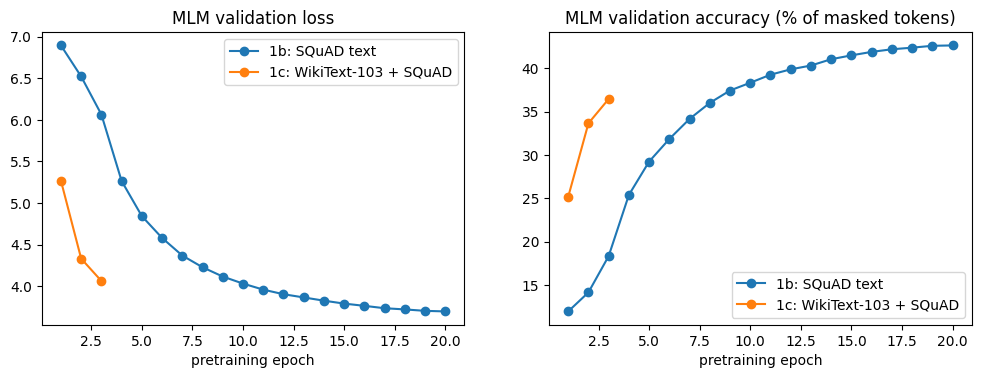

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for name, label in [("scratch_squad_mlm", "1b: SQuAD text"), ("scratch_wiki_mlm", "1c: WikiText-103 + SQuAD")]:
    with open(f"{model_dir(name)}/info.json") as f:
        log = json.load(f)["mlm_log"]
    axes[0].plot([h["epoch"] for h in log], [h["val_loss"] for h in log], marker="o", label=label)
    axes[1].plot([h["epoch"] for h in log], [100 * h["val_acc"] for h in log], marker="o", label=label)
axes[0].set_title("MLM validation loss")
axes[1].set_title("MLM validation accuracy (% of masked tokens)")
for ax in axes:
    ax.set_xlabel("pretraining epoch")
    ax.legend()
save_fig("mlm_pretraining.png")

An epoch of 1b is one pass over 83k question-paragraph pairs, an epoch of 1c one pass over about 500k blocks of text, so the two curves do not share an x scale.

## 6. Approaches 2 and 3: fine-tuning pretrained models

Pretrained encoders already know a lot about English, so they need much less task data than a model trained from scratch. Both have the BERT-base size (12 layers, hidden size 768). We add a new start/end layer and fine-tune all weights.

* Approach 2, ELECTRA-base (`google/electra-base-discriminator`): pretrained to detect replaced tokens, which works very well on SQuAD for its size. The input is cut at 384 tokens; only about 1% of the questions are longer.
* Approach 3, RoBERTa-base (`roberta-base`): BERT trained longer on more data. Here we use windows of 384 tokens with stride 128, so every answer can be found, also in very long paragraphs.

Settings: 2 epochs, AdamW, 10% warmup, weight decay 0.01, fp16. ELECTRA: lr 5e-5, batch 16. RoBERTa: lr 3e-5, batch 16 with 2 gradient accumulation steps.

In [23]:
def train_pretrained(name, model_name, max_len, stride, use_windows, lr, batch_size, grad_accum, epochs=2, train_data=None):
    tok = AutoTokenizer.from_pretrained(model_name)
    train_feats = make_features(train_data if train_data is not None else train_set, tok, max_len, stride, use_windows)
    val_feats = make_features(val_set, tok, max_len, stride, use_windows)
    model = AutoModelForQuestionAnswering.from_pretrained(model_name)
    steps = epochs * len(train_feats) // (batch_size * grad_accum)
    args = TrainingArguments(output_dir=f"/content/tmp_{name}", num_train_epochs=epochs, learning_rate=lr,
                             per_device_train_batch_size=batch_size, gradient_accumulation_steps=grad_accum,
                             per_device_eval_batch_size=64, warmup_steps=int(0.1 * steps), weight_decay=0.01, fp16=True,
                             eval_strategy="epoch", save_strategy="no", logging_steps=100, report_to="none", seed=SEED,
                             disable_tqdm=True)
    trainer = Trainer(model=model, args=args, data_collator=default_data_collator,
                      train_dataset=train_feats.remove_columns(["offset_mapping", "example_id"]),
                      eval_dataset=val_feats.remove_columns(["offset_mapping", "example_id"]))
    torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    trainer.train()
    info = {"train_log": [{"epoch": h["epoch"], "loss": h["loss"]} for h in trainer.state.log_history if "loss" in h],
            "val_log": [{"epoch": h["epoch"], "loss": h["eval_loss"]} for h in trainer.state.log_history if "eval_loss" in h],
            "train_seconds": time.time() - t0, "train_gpu_gb": torch.cuda.max_memory_allocated() / 1e9, "epochs": epochs}
    return trainer, tok, info


def train_and_save(name, *args, **kwargs):
    trainer, tok, info = train_pretrained(name, *args, **kwargs)
    folder = model_dir(name)
    trainer.save_model(folder)
    tok.save_pretrained(folder)
    with open(f"{folder}/qa_run_config.json", "w") as f:
        json.dump({"kind": "hf", "max_len": args[1], "stride": args[2] or 128}, f)
    with open(f"{folder}/info.json", "w") as f:
        json.dump(info, f)
    upload(f"models/{FOLDER[name]}")


for name, settings in [("electra", ("google/electra-base-discriminator", 384, 0, False, 5e-5, 16, 1)),
                       ("roberta", ("roberta-base", 384, 128, True, 3e-5, 16, 2))]:
    if not fetch_model(name):
        train_and_save(name, *settings)

downloaded electra
downloaded roberta


## 7. Results

### 7.1 Scores of all models

Every model is scored on validation (to compare models) and on the test set (final scores). The scores are saved, so the models are only run once.

In [24]:
MODELS = {"scratch": "1a Scratch", "scratch_squad_mlm": "1b Scratch + SQuAD MLM",
          "scratch_wiki_mlm": "1c Scratch + WikiText MLM", "electra": "2 ELECTRA-base (truncation)",
          "roberta": "3 RoBERTa-base (windows)"}
RESULTS_FILE = f"{OUT}/results/scores.json"
scores = json.load(open(RESULTS_FILE)) if os.path.exists(RESULTS_FILE) else {}

for name in MODELS:
    if name in scores:
        continue
    model, config, info = load_model(name)
    tok = AutoTokenizer.from_pretrained(TOKENIZER_OF[name.split("_")[0]])
    windows = name == "roberta"
    val, _ = evaluate_model(model, val_set, make_features(val_set, tok, config["max_len"], config["stride"], windows))
    test_feats = make_features(test_set, tok, config["max_len"], config["stride"], windows)
    test, preds = evaluate_model(model, test_set, test_feats)
    with open(f"{OUT}/results/test_predictions_{name}.json", "w") as f:
        json.dump(preds, f)
    upload(f"results/test_predictions_{name}.json")
    scores[name] = {"val": val, "test": test, "params": sum(p.numel() for p in model.parameters()),
                    "test_inputs_per_question": len(test_feats) / len(test_set), "test_answer_lost": answer_cutoff(test_set, test_feats)}
    with open(RESULTS_FILE, "w") as f:
        json.dump(scores, f)
    upload("results/scores.json")
    del model
    torch.cuda.empty_cache()

infos = {name: json.load(open(f"{model_dir(name)}/info.json")) for name in MODELS}
results = pd.DataFrame([{"model": label, "val EM": scores[n]["val"]["em"], "val F1": scores[n]["val"]["f1"],
                         "test EM": scores[n]["test"]["em"], "test F1": scores[n]["test"]["f1"],
                         "params (M)": scores[n]["params"] / 1e6,
                         "train min": (infos[n]["train_seconds"] + infos[n].get("mlm_seconds", 0)) / 60,
                         "train GPU (GB)": infos[n]["train_gpu_gb"],
                         "test s / 1000 questions": scores[n]["test"]["seconds_per_1000"],
                         "test GPU (GB)": scores[n]["test"]["inference_gpu_gb"]} for n, label in MODELS.items()]).round(2)
results.to_csv(f"{OUT}/results/main_results.csv", index=False)
upload("results/main_results.csv")
results

,model,val EM,val F1,test EM,test F1,params (M),train min,train GPU (GB),test s / 1000 questions,test GPU (GB)
0,1a Scratch,31.04,45.96,34.90,47.97,22.47,65.72,0.60,2.35,0.33
1,1b Scratch + SQuAD MLM,48.96,63.97,55.98,67.37,22.47,129.07,0.60,2.34,0.33
2,1c Scratch + WikiText MLM,45.53,60.18,51.17,63.41,22.47,141.82,0.69,2.32,0.33
3,2 ELECTRA-base (truncation),71.94,85.41,85.33,91.89,108.89,50.24,4.09,7.68,1.22
4,3 RoBERTa-base (windows),72.04,85.23,86.04,92.16,124.06,49.37,4.77,7.53,1.28


Training time includes the MLM pretraining of 1b and 1c. All times are on a T4 GPU.

RoBERTa has the best test scores (86.04 EM, 92.16 F1) and ELECTRA the best validation F1 (85.41); the two are within 0.3 F1 of each other. Both are about 44 test F1 better than 1a. MLM pretraining helps the scratch model a lot: +19.4 test F1 for 1b and +15.4 for 1c. 1c is 4 F1 behind 1b, see 7.2.

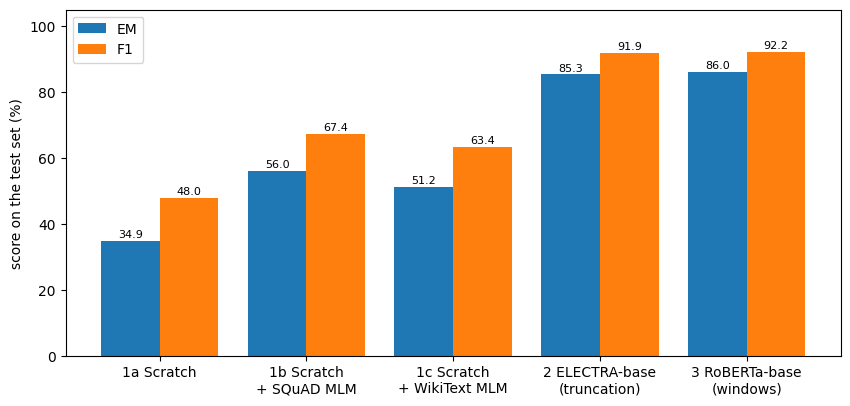

In [25]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(results))
ax.bar(x - 0.2, results["test EM"], width=0.4, label="EM")
ax.bar(x + 0.2, results["test F1"], width=0.4, label="F1")
for i, (em, f1) in enumerate(zip(results["test EM"], results["test F1"])):
    ax.text(i - 0.2, em + 1, f"{em:.1f}", ha="center", fontsize=8)
    ax.text(i + 0.2, f1 + 1, f"{f1:.1f}", ha="center", fontsize=8)
ax.set_xticks(x, [label.replace(" (", "\n(").replace(" + ", "\n+ ") for label in results["model"]])
ax.set_ylabel("score on the test set (%)")
ax.set_ylim(0, 105)
ax.legend()
save_fig("test_scores.png")

### 7.2 Training and validation curves

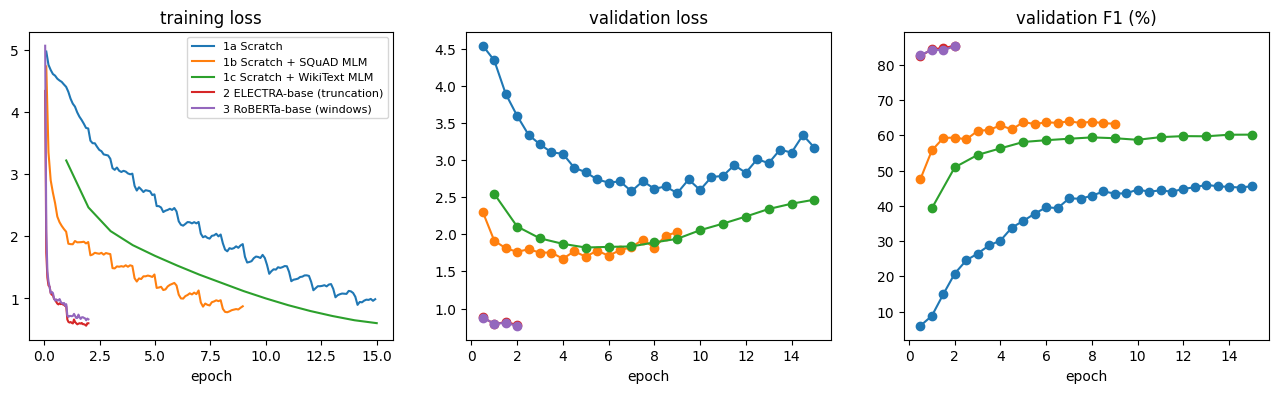

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for name, label in MODELS.items():
    info = infos[name]
    line, = axes[0].plot([h["epoch"] for h in info["train_log"]], [h["loss"] for h in info["train_log"]], label=label)
    axes[1].plot([h["epoch"] for h in info["val_log"]], [h["loss"] for h in info["val_log"]], marker="o", color=line.get_color())
    f1_points = [h for h in info["val_log"] if "f1" in h]
    if f1_points:
        axes[2].plot([h["epoch"] for h in f1_points], [h["f1"] for h in f1_points], marker="o", color=line.get_color())
for ax, title in zip(axes, ["training loss", "validation loss", "validation F1 (%)"]):
    ax.set_title(title)
    ax.set_xlabel("epoch")
axes[0].legend(fontsize=8)
save_fig("training_curves.png")

1a overfits: its training loss keeps going down while the validation loss rises after epoch 9. Validation F1 still improves for a while, because the model gets more confident on wrong answers (higher loss) while it ranks more right answers first (higher F1). That is why we keep the weights with the best F1, not the lowest loss. The two pretrained scratch models start much higher, and ELECTRA and RoBERTa reach good scores within 2 epochs.

Why is 1c worse than 1b? Its pretraining was stopped while it was still improving fast: after 3 epochs the masked-token accuracy on the validation paragraphs was about 36% and rising steeply, while 1b reached 42.6% after 20 epochs. 1b was also pretrained on SQuAD question-paragraph pairs, so it had already seen questions and the exact paragraphs it is later trained on. 1c only saw plain Wikipedia text. With the pretraining time we had on a T4, in-domain text was the better choice. 1c's fine-tuning ran into the 15-epoch limit with validation F1 almost flat (59.7, 60.2, 60.2 in the last three epochs).

## 8. Experiments

### 8.1 Effect of shortening the input

The trained ELECTRA and RoBERTa models get inputs of 128, 256 and 384 tokens on the validation set, once with truncation and once with windows (stride 32, 64 and 128). The models are not retrained, only the input length changes.

In [27]:
TRUNC_FILE = f"{OUT}/results/input_length_study.csv"
if os.path.exists(TRUNC_FILE):
    length_study = pd.read_csv(TRUNC_FILE)
else:
    rows = []
    for name in ["electra", "roberta"]:
        model, config, info = load_model(name)
        tok = AutoTokenizer.from_pretrained(TOKENIZER_OF[name])
        for max_len, stride in [(128, 32), (256, 64), (384, 128)]:
            for windows in [False, True]:
                feats = make_features(val_set, tok, max_len, stride, windows)
                val, _ = evaluate_model(model, val_set, feats)
                rows.append({"model": MODELS[name], "max length": max_len, "windows": windows, "val EM": val["em"],
                             "val F1": val["f1"], "answers lost (%)": answer_cutoff(val_set, feats),
                             "inputs per question": len(feats) / len(val_set)})
        del model
        torch.cuda.empty_cache()
    length_study = pd.DataFrame(rows)
    length_study.to_csv(TRUNC_FILE, index=False)
    upload("results/input_length_study.csv")
length_study.round(2)

,model,max length,windows,val EM,val F1,answers lost (%),inputs per question
0,2 ELECTRA-base (truncation),128,False,59.84,71.26,19.56,1.00
1,2 ELECTRA-base (truncation),128,True,70.83,83.75,0.05,2.05
2,2 ELECTRA-base (truncation),256,False,71.52,84.90,0.82,1.00
3,2 ELECTRA-base (truncation),256,True,71.89,85.29,0.00,1.08
4,2 ELECTRA-base (truncation),384,False,71.94,85.41,0.02,1.00
5,2 ELECTRA-base (truncation),384,True,71.92,85.40,0.00,1.01
6,3 RoBERTa-base (windows),128,False,57.98,69.68,21.30,1.00
7,3 RoBERTa-base (windows),128,True,70.10,83.02,0.05,2.10
8,3 RoBERTa-base (windows),256,False,71.60,84.68,0.92,1.00
9,3 RoBERTa-base (windows),256,True,71.97,85.17,0.00,1.09


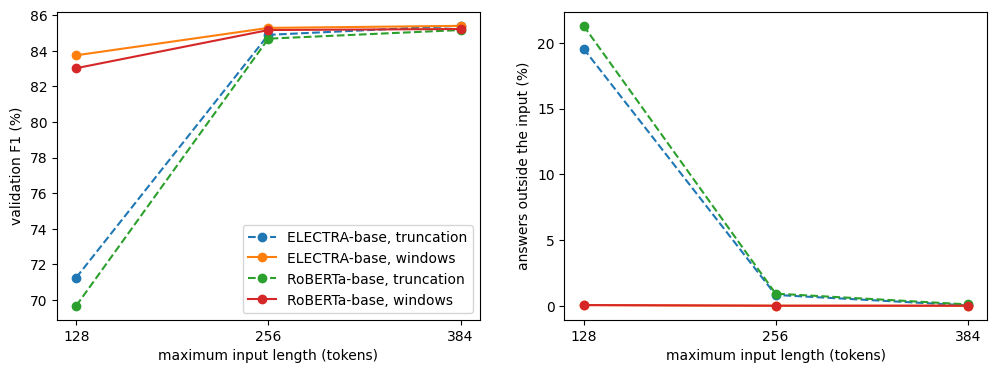

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for (model_name, windows), group in length_study.groupby(["model", "windows"]):
    style = "-" if windows else "--"
    label = f"{model_name.split(' (')[0][2:]}, {'windows' if windows else 'truncation'}"
    axes[0].plot(group["max length"], group["val F1"], style, marker="o", label=label)
    axes[1].plot(group["max length"], group["answers lost (%)"], style, marker="o", label=label)
axes[0].set_ylabel("validation F1 (%)")
axes[1].set_ylabel("answers outside the input (%)")
for ax in axes:
    ax.set_xticks([128, 256, 384])
    ax.set_xlabel("maximum input length (tokens)")
axes[0].legend()
save_fig("input_length.png")

Cutting the input to 128 tokens loses about 20% of the answers and costs 14.2 F1 for ELECTRA (85.41 to 71.26) and 15.5 for RoBERTa (85.17 to 69.68). With windows almost no answer is lost and most of the score comes back: 83.75 F1 for ELECTRA and 83.02 for RoBERTa. The remaining gap of about 2 F1 comes from the short context, since a 128-token window leaves little of the paragraph next to the question and both models were trained on 384 tokens. At 256 tokens windows add 0.4 to 0.5 F1, and at 384 tokens they make almost no difference because only 1% of the inputs are longer.

### 8.2 Effect of the amount of training data

ELECTRA-base trained for one epoch on 10%, 25%, 50% and 100% of the training questions (each smaller set is part of the bigger ones). The four runs take about 49 minutes; the table is saved in the repository, so they only run once.

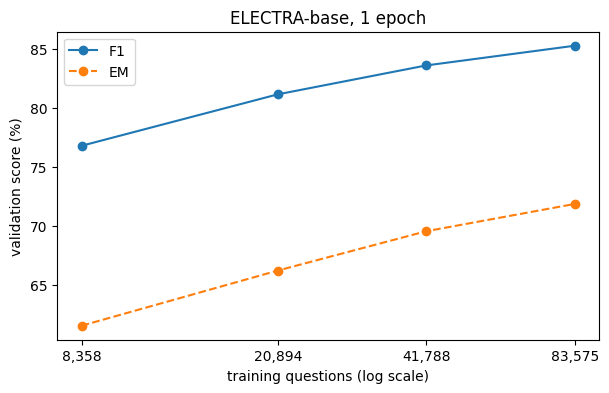

,fraction,train questions,val EM,val F1,train min
0,0.10,8358,61.53,76.77,3.31
1,0.25,20894,66.20,81.12,6.99
2,0.50,41788,69.53,83.57,13.10
3,1.00,83575,71.84,85.24,25.15


In [29]:
SIZE_FILE = f"{OUT}/results/data_size_val.csv"
if not os.path.exists(SIZE_FILE):
    order = np.random.RandomState(SEED).permutation(len(train_set))
    rows = []
    for fraction in [0.1, 0.25, 0.5, 1.0]:
        subset = train_set.select(sorted(order[:round(fraction * len(train_set))]))
        trainer, tok, info = train_pretrained("size", "google/electra-base-discriminator", 384, 0, False,
                                              5e-5, 16, 1, epochs=1, train_data=subset)
        val, _ = evaluate_model(trainer.model, val_set, make_features(val_set, tok, 384))
        rows.append({"fraction": fraction, "train questions": len(subset), "val EM": val["em"], "val F1": val["f1"],
                     "train min": info["train_seconds"] / 60})
        del trainer
        torch.cuda.empty_cache()
    pd.DataFrame(rows).to_csv(SIZE_FILE, index=False)
    upload("results/data_size_val.csv")

size_study = pd.read_csv(SIZE_FILE).drop(columns="status", errors="ignore")
plt.figure(figsize=(7, 4))
plt.plot(size_study["train questions"], size_study["val F1"], marker="o", label="F1")
plt.plot(size_study["train questions"], size_study["val EM"], marker="o", linestyle="--", label="EM")
plt.xscale("log")
plt.xticks(size_study["train questions"], [f"{n:,}" for n in size_study["train questions"]])
plt.minorticks_off()
plt.xlabel("training questions (log scale)")
plt.ylabel("validation score (%)")
plt.title("ELECTRA-base, 1 epoch")
plt.legend()
save_fig("data_size.png")
size_study.round(2)

10% of the data (8,358 questions) already gives 76.8 validation F1, which is 90% of the full-data score after one epoch. Each doubling adds less: +4.4, +2.5 and +1.7 F1.

### 8.3 Effect of the architecture

The models differ in several things at once (size, vocabulary, pretraining, input length), so this is not a clean comparison of one factor. 1a, 1b and 1c share the same architecture and only differ in pretraining. ELECTRA and RoBERTa have the same size and differ in pretraining and in how long paragraphs are handled.

In [30]:
pd.DataFrame([
    {"model": MODELS["scratch"], "layers": 6, "hidden": 384, "heads": 6, "vocabulary": 30522, "pretraining": "none", "max length": 256},
    {"model": MODELS["scratch_squad_mlm"], "layers": 6, "hidden": 384, "heads": 6, "vocabulary": 30522, "pretraining": "MLM, SQuAD train text", "max length": 256},
    {"model": MODELS["scratch_wiki_mlm"], "layers": 6, "hidden": 384, "heads": 6, "vocabulary": 30522, "pretraining": "MLM, WikiText-103 + SQuAD paragraphs", "max length": 256},
    {"model": MODELS["electra"], "layers": 12, "hidden": 768, "heads": 12, "vocabulary": 30522, "pretraining": "ELECTRA (Google)", "max length": 384},
    {"model": MODELS["roberta"], "layers": 12, "hidden": 768, "heads": 12, "vocabulary": 50265, "pretraining": "RoBERTa (Facebook)", "max length": 384},
]).merge(results[["model", "params (M)", "val F1", "test F1"]], on="model")

,model,layers,hidden,heads,vocabulary,pretraining,max length,params (M),val F1,test F1
0,1a Scratch,6,384,6,30522,none,256,22.47,45.96,47.97
1,1b Scratch + SQuAD MLM,6,384,6,30522,"MLM, SQuAD train text",256,22.47,63.97,67.37
2,1c Scratch + WikiText MLM,6,384,6,30522,"MLM, WikiText-103 + SQuAD paragraphs",256,22.47,60.18,63.41
3,2 ELECTRA-base (truncation),12,768,12,30522,ELECTRA (Google),384,108.89,85.41,91.89
4,3 RoBERTa-base (windows),12,768,12,50265,RoBERTa (Facebook),384,124.06,85.23,92.16


The size of the encoder is not what separates the models most: the same 22.5M-parameter encoder goes from 48 to 67 test F1 just by pretraining, and the two base models of the same size end up almost equal.

### 8.4 Accuracy against training time

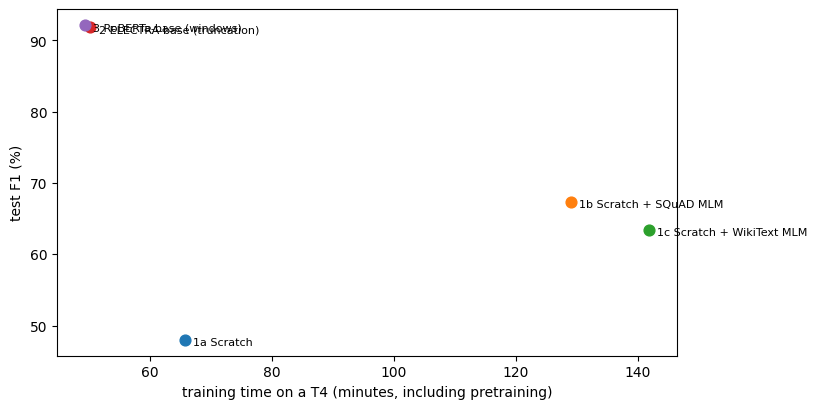

In [31]:
plt.figure(figsize=(8, 4.5))
for _, row in results.iterrows():
    plt.scatter(row["train min"], row["test F1"], s=60)
    plt.annotate(row["model"], (row["train min"], row["test F1"]), textcoords="offset points", xytext=(6, -4), fontsize=8)
plt.xlabel("training time on a T4 (minutes, including pretraining)")
plt.ylabel("test F1 (%)")
save_fig("time_vs_f1.png")

ELECTRA and RoBERTa give by far the best F1 for their training time because they start from pretrained weights. 1c took the longest (142 minutes including pretraining) and still ends behind 1b.

## 9. Error analysis

We look at the test predictions of ELECTRA-base, the model with the best validation F1. A prediction counts as wrong when its EM is 0.

In [32]:
with open(f"{OUT}/results/test_predictions_electra.json") as f:
    preds = json.load(f)

rows = []
for ex, a_type in zip(test_set, test_types):
    pred = preds[ex["id"]]
    em, f1 = score(pred["text"], ex["answers"]["text"])
    closest = max(ex["answers"]["text"], key=lambda g: f1_score(pred["text"], g))
    rows.append({"question": ex["question"], "context": ex["context"], "gold": closest, "all golds": ex["answers"]["text"],
                 "prediction": pred["text"], "pred start": pred["start"], "EM": em, "F1": f1, "answer type": a_type})
analysis = pd.DataFrame(rows)
errors = analysis[analysis["EM"] == 0].copy()
print(f"{len(errors)} of {len(analysis)} test questions are wrong ({100 * len(errors) / len(analysis):.1f}%)")

by_type = analysis.groupby("answer type")[["EM", "F1"]].mean().reindex(ANSWER_TYPES) * 100
by_type.insert(0, "questions", analysis["answer type"].value_counts())
by_type.round(2)

1551 of 10570 test questions are wrong (14.7%)


,questions,EM,F1
answer type,,,
Date,1203,92.93,96.48
Number,1367,86.54,92.83
Name,2550,91.06,94.05
Single word,1410,85.18,90.57
Multi-word,4040,79.08,89.31


Dates and names are the easiest, multi-word answers the hardest for EM: a long answer has more ways to start or end a word too early or too late.

Every wrong answer goes into one of three groups, using the gold answer closest to the prediction:
* boundary error: the prediction overlaps the gold answer but has words too many or too few
* wrong entity of the same type: both are dates, numbers or names, but the model picked another one
* wrong part of the paragraph: everything else

In [33]:
def error_type(row):
    if row["F1"] > 0:
        return "Boundary error"
    doc = docs[row["context"]]
    if pd.isna(row["pred start"]):
        return "Wrong part of the paragraph"
    start = int(row["pred start"])
    pred_type = answer_type(row["prediction"], entity_labels(doc, start, start + len(row["prediction"])))
    if pred_type == row["answer type"] and pred_type in ["Date", "Number", "Name"]:
        return "Wrong entity of the same type"
    return "Wrong part of the paragraph"

errors["error type"] = errors.apply(error_type, axis=1)
error_table = pd.crosstab(errors["answer type"], errors["error type"], margins=True).reindex(ANSWER_TYPES + ["All"])
error_table.to_csv(f"{OUT}/results/error_types.csv")
upload("results/error_types.csv")
error_table

error type,Boundary error,Wrong entity of the same type,Wrong part of the paragraph,All
answer type,,,,
Date,66,15,4,85
Number,134,32,18,184
Name,125,78,25,228
Single word,139,0,70,209
Multi-word,648,0,197,845
All,1112,125,314,1551


1,112 of the 1,551 wrong answers (72%) are boundary errors, 125 (8%) pick another entity of the same type and 314 (20%) come from another part of the paragraph.

### 9.1 Twelve wrong answers read by hand

12 wrong answers picked at random (3 dates, 3 numbers, 3 names, 1 single word, 2 multi-word), each read to see why the model got it wrong.

In [34]:
NOTES = {
    "Deacons serve a term of how many years as provisional deacons?":
        "Stops before the unit: '2-3' instead of '2-3 years'.",
    "In what year was the Super Bowl last held in the Miami/South Florida area?":
        "The next sentence (about the San Francisco Bay Area) repeats the words 'last hosted' from the question.",
    "What age does basic education start?":
        "Not really wrong: 'six years' lies between the accepted answers 'age six years' and 'six'.",
    "How many first downs did the Panthers have in Super Bowl 50?":
        "In 'first downs (21 to 11)' the model has to know the first number is Carolina's. It takes a number from another statistic.",
    "What is the population of the second largest city in California?":
        "Needs two steps: find that San Diego is the second largest city, then its population.",
    "How large are Chloroplast ribosomes?":
        "Copies the whole comparison '17 nm vs 25 nm' instead of only the chloroplast size.",
    "Where was Parliament's temporary home whilst the permanent building was being built?":
        "Not really wrong: the right place plus 'on the Royal Mile in Edinburgh'.",
    "To whom did Luther send a letter containing his 95 Theses?":
        "The sentence is negative ('did not reply to Luther's letter'), the model picks 'Rome' instead.",
    "Who was the Denver head coach for Super Bowl 50?":
        "John Fox was the coach before. The paragraph says Gary Kubiak replaced him, so this needs reasoning about time.",
    "How does the secondary theory say most cpDNA is structured?":
        "The answer runs on into the next clause ('and replicates through homologous recombination').",
    "Gamma delta T cells have a different version of what receptor?":
        "Not really wrong: the accepted answer without '(TCR)'. EM counts it as wrong.",
    "Huguenots in Killeshandra and County Cavan expanded what agricultural industry?":
        "Runs on into the next item of the list and stops in the middle of a phrase.",
}
examples = errors[errors["question"].isin(NOTES)].copy()
examples["why"] = examples["question"].map(NOTES)
examples[["answer type", "question", "all golds", "prediction", "F1", "error type", "why"]]

,answer type,question,all golds,prediction,F1,error type,why
143,Date,In what year was the Super Bowl last held in t...,"[2010, 2010, 2010]",1985,0.000000,Wrong entity of the same type,The next sentence (about the San Francisco Bay...
267,Name,Who was the Denver head coach for Super Bowl 50?,"[Gary Kubiak, Gary Kubiak, Kubiak]",John Fox,0.000000,Wrong entity of the same type,John Fox was the coach before. The paragraph s...
805,Number,How many first downs did the Panthers have in ...,"[21, 21, 21]",3-of-15,0.000000,Wrong entity of the same type,In 'first downs (21 to 11)' the model has to k...
2247,Name,To whom did Luther send a letter containing hi...,"[Archbishop Albrecht, Archbishop Albrecht, Arc...",Rome,0.000000,Wrong entity of the same type,The sentence is negative ('did not reply to Lu...
2736,Number,What is the population of the second largest c...,"[1.3 million, 1.3 million, San Diego]","100,000",0.000000,Wrong entity of the same type,Needs two steps: find that San Diego is the se...
3191,Multi-word,Huguenots in Killeshandra and County Cavan exp...,"[flax cultivation, flax, flax cultivation]",flax cultivation and the growth of the Irish l...,0.444444,Boundary error,Runs on into the next item of the list and sto...
6593,Multi-word,Gamma delta T cells have a different version o...,"[alternative T cell receptor (TCR), T cell, T ...",T cell receptor,0.857143,Boundary error,Not really wrong: the accepted answer without ...
8548,Date,What age does basic education start?,"[age six years, six, six]",six years,0.800000,Boundary error,Not really wrong: 'six years' lies between the...
8798,Single word,How does the secondary theory say most cpDNA i...,"[linear, linear, linear]",linear and replicates through homologous recom...,0.285714,Boundary error,The answer runs on into the next clause ('and ...
8840,Number,How large are Chloroplast ribosomes?,"[17 nm, around 17 nm, 17 nm]",17 nm vs 25 nm,0.571429,Boundary error,Copies the whole comparison '17 nm vs 25 nm' i...


What we see in the errors:
* Most errors are boundary errors. The model finds the right place but includes or leaves out a word, a unit or a clause, which is also why F1 is much higher than EM.
* When the model picks the wrong entity, there is usually another date, number or name close to words from the question.
* Some questions need a step that span matching cannot do: combining two facts, a negation, or the order of events.
* Three of the twelve are actually correct answers that EM counts as wrong.

## 10. Using the trained models

`inference.py` loads any of the models and answers a question without this notebook. It uses the same windows as above, so long paragraphs work too.

In [35]:
%%writefile {OUT}/inference.py
"""Answer a question with one of the trained SQuAD models.

    python inference.py --model-dir models/electra_56b9af30 \
        --question "In which year did Alan Turing introduce the Turing machine?" \
        --context "Alan Turing was a British mathematician and computer scientist. He introduced the concept of the Turing machine in 1936."
"""
import argparse
import json
import os

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoModelForQuestionAnswering, AutoTokenizer


class ScratchQAModel(nn.Module):   # same as in the notebook
    def __init__(self, vocab_size, hidden=384, layers=6, heads=6, ff_dim=1536, max_len=256, dropout=0.1, pad_id=0):
        super().__init__()
        self.token_emb = nn.Embedding(vocab_size, hidden, padding_idx=pad_id)
        self.pos_emb = nn.Embedding(max_len, hidden)
        self.seg_emb = nn.Embedding(2, hidden)
        self.match_emb = nn.Embedding(2, hidden)
        self.emb_norm = nn.LayerNorm(hidden)
        self.emb_drop = nn.Dropout(dropout)
        layer = nn.TransformerEncoderLayer(hidden, heads, ff_dim, dropout, activation="gelu", batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, layers, norm=nn.LayerNorm(hidden), enable_nested_tensor=False)
        self.start_head = nn.Linear(hidden, 1)
        self.end_head = nn.Linear(hidden, 1)

    def forward(self, input_ids, attention_mask, token_type_ids):
        positions = torch.arange(input_ids.size(1), device=input_ids.device)
        question = (token_type_ids == 0) & (attention_mask == 1)
        match = ((input_ids[:, :, None] == input_ids[:, None, :]) & question[:, None, :]).any(-1).long()
        x = self.token_emb(input_ids) + self.pos_emb(positions) + self.seg_emb(token_type_ids) + self.match_emb(match)
        h = self.encoder(self.emb_drop(self.emb_norm(x)), src_key_padding_mask=attention_mask == 0)
        padding = attention_mask == 0
        return self.start_head(h).squeeze(-1).masked_fill(padding, -1e4), self.end_head(h).squeeze(-1).masked_fill(padding, -1e4)


def make_windows(tokenizer, question, context, max_len, stride):
    windows, start = [], 0
    while True:
        cut = start - 1 if start > 0 and context[start - 1].isspace() else start
        enc = tokenizer(question, context[cut:], truncation="only_second", max_length=max_len,
                        padding="max_length", return_offsets_mapping=True)
        seq_ids = enc.sequence_ids()
        enc["offset_mapping"] = [(a + cut, b + cut) if s == 1 else None for (a, b), s in zip(enc["offset_mapping"], seq_ids)]
        windows.append(enc)
        if sum(enc["attention_mask"]) < max_len:
            return windows
        ctx = [i for i, s in enumerate(seq_ids) if s == 1]
        j = max(1, len(ctx) - stride)
        while j > 1 and not context[enc["offset_mapping"][ctx[j]][0] - 1].isspace():
            j -= 1
        start = enc["offset_mapping"][ctx[j]][0]


def load(model_dir, device):
    with open(os.path.join(model_dir, "qa_run_config.json")) as f:
        config = json.load(f)
    tokenizer = AutoTokenizer.from_pretrained(model_dir)
    if config["kind"] == "scratch":
        model = ScratchQAModel(**config["arch"])
        model.load_state_dict(torch.load(os.path.join(model_dir, "best_model.pt"), map_location="cpu"))
    else:
        model = AutoModelForQuestionAnswering.from_pretrained(model_dir)
    return model.to(device).eval(), tokenizer, config


@torch.no_grad()
def answer(question, context, model, tokenizer, config, n_best=20, max_answer_len=30):
    device = next(model.parameters()).device
    windows = make_windows(tokenizer, question.strip(), context, config["max_len"], config["stride"])
    inputs = {k: torch.tensor([w[k] for w in windows], device=device)
              for k in ["input_ids", "attention_mask", "token_type_ids"] if k in windows[0]}
    if isinstance(model, ScratchQAModel):
        start, end = model(**inputs)
    else:
        out = model(**inputs)
        start, end = out.start_logits, out.end_logits
    start, end = start.float().cpu().numpy(), end.float().cpu().numpy()
    best_text, best_score = "", -1e9
    for i, w in enumerate(windows):
        offsets = w["offset_mapping"]
        for s in np.argsort(start[i])[-n_best:]:
            for e in np.argsort(end[i])[-n_best:]:
                if offsets[s] is None or offsets[e] is None or e < s or e - s + 1 > max_answer_len:
                    continue
                if start[i][s] + end[i][e] > best_score:
                    best_text, best_score = context[offsets[s][0]:offsets[e][1]], float(start[i][s] + end[i][e])
    return best_text, best_score


if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument("--model-dir", required=True)
    parser.add_argument("--question", required=True)
    parser.add_argument("--context", required=True)
    args = parser.parse_args()
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model, tokenizer, config = load(args.model_dir, device)
    text, score = answer(args.question, args.context, model, tokenizer, config)
    print(f"Answer: {text} (score {score:.2f})")

Writing /content/squad_qa/inference.py


In [37]:
upload("inference.py")
import sys
sys.path.append(OUT)
import inference

turing = ("Alan Turing was a British mathematician and computer scientist. "
          "He introduced the concept of the Turing machine in 1936.")
long_paragraph = " ".join(sorted(set(test_set["context"]))[:4]) + " " + turing
question = "In which year did Alan Turing introduce the Turing machine?"

rows = []
for name, label in MODELS.items():
    model, tok, config = inference.load(model_dir(name), device)
    short, _ = inference.answer(question, turing, model, tok, config)
    long, _ = inference.answer(question, long_paragraph, model, tok, config)
    rows.append({"model": label, "short paragraph": short, "long paragraph": long,
                 "windows for the long paragraph": len(inference.make_windows(tok, question, long_paragraph, config["max_len"], config["stride"]))})
    del model
pd.DataFrame(rows)

,model,short paragraph,long paragraph,windows for the long paragraph
0,1a Scratch,1936,1936,4
1,1b Scratch + SQuAD MLM,1936,1936,4
2,1c Scratch + WikiText MLM,1936,1936,4
3,2 ELECTRA-base (truncation),1936,1936,3
4,3 RoBERTa-base (windows),1936,1936,3


In the long paragraph the Turing sentences come after four other test paragraphs, so the input is split into 3 or 4 windows and the answer is in the last one. All five models still find 1936.

## 11. Conclusion

Fine-tuning a pretrained encoder works best. RoBERTa-base with windows has the best test scores (86.04 EM, 92.16 F1) and ELECTRA-base the best validation F1 (85.41). The difference is a few tenths of a point, which is within the noise of a single run. ELECTRA is smaller (108.9M vs 124.1M parameters) and needs less memory; RoBERTa never cuts off an answer in long paragraphs.

Pretraining is the main reason these models win. Our scratch encoder alone reaches 47.97 test F1 and overfits. Pretraining the same encoder with MLM adds 19.4 F1 with the SQuAD text (1b) and 15.4 F1 with WikiText-103 (1c). More general text did not pay off within our budget: 1c needed more time and ended 4 F1 behind 1b.

Input length matters only when answers are cut off: 384 tokens are enough for SQuAD, and at 128 tokens windows bring the score back from about 70 to 83 F1. For ELECTRA, a tenth of the training data already gives 90% of the full score. About 72% of ELECTRA's errors are boundary errors.

| Approach | Test F1 | Strengths | Weaknesses |
|---|---|---|---|
| 1a Scratch | 47.97 | small (22.5M parameters), fast, no outside data | overfits, no knowledge of English |
| 1b Scratch + SQuAD MLM | 67.37 | +19.4 F1 over 1a without outside data | still about 25 F1 behind the pretrained models |
| 1c Scratch + WikiText MLM | 63.41 | +15.4 F1 over 1a | longest training (142 min), worse than 1b |
| 2 ELECTRA-base | 91.89 | best validation F1, smaller than RoBERTa | answers after 384 tokens are lost |
| 3 RoBERTa-base | 92.16 | best test scores, every answer can be found | largest model, windows add only about 1% more inputs |

Limitations: one run per model, so differences of a few tenths of a point are noise; answer types and error groups come from simple rules; training times depend on the GPU.